# Gravitational Waves Course, MPI (2026)

## Homework 6: Use of Simulating eXtreme Spacetimes package (sxs)

### Useful articles:

1. Gravitational waveform catalogs:
-  Scheel et al, CQG 42 195017 (2025), https://arxiv.org/abs/2505.13378

2. Black hole kicks
- Gonzalez et al, PRL 98 091101 (2007), https://arxiv.org/abs/gr-qc/0610154
-  Ruiz et al, GRG 40 1705 (2008), https://arxiv.org/abs/0707.4654



### Problem 1: Finding & obtaining simulations
The 'sxs' package provides access to the simulation metadata and gravitational-wave data.


In [35]:
# Installation of sxs

%pip install sxs


### Download simulations:
We use the six non-spinning binary black hole simulations:
'1143', '1222', '1178', '1220', '192', '1108'.


We first enable local caching, load the simulation catalog, and then download the waveforms using extrapolation order 2.

In [36]:
# Download six SXS simulations

import sxs

# Enable caching
sxs.write_config(download=True, cache=True)

# Download metadata
catalog = sxs.load("simulations")

# List of simulations to work with
IDs = [
    'SXS:BBH:1143',
    'SXS:BBH:1222',
    'SXS:BBH:1178',
    'SXS:BBH:1220',
    'SXS:BBH:0192',
    'SXS:BBH:1108'
]

# Download waveforms into 'wf' dictionary
wf = {}

for k in IDs:
    wf[k] = sxs.load(k, extrapolation_order=2)

### Accessing waveform data and simulation metadata

The SXS catalog provides two relevant objects:

- 'catalog': contains the metadata associated with each numerical-relativity simulation.
- 'wf': contains the gravitational-wave waveform data.

We extract the reference mass ratio $q$, the remnant mass $m_f$, the time array $t$, and the real part of the $(2,2)$ waveform mode.


In [37]:
# Useful libraries

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [38]:

# Access waveform data and simulation metadata


# Illustrate how to use the waveforms from the catalog
for sxs_id in wf:

    print("sxs_id =", sxs_id)

    # Retrieve metadata
    sim = catalog[sxs_id]

    q = sim['reference_mass_ratio']
    mf = sim['remnant_mass']

    print(f"    mass-ratio {q}, remnant mass {mf}")

    # Retrieve time and Re(h22) mode

    w = wf[sxs_id].h

    t = np.array(w.t)

    l = 2
    m = 2

    Reh22 = np.array(np.real(w[:, w.index(l, m)]))   # Real part of the mode 2,2

    # Print some information about waveform
    tstart = t[0]
    tend = t[-1]

    print(f"    time range covered by waveform: [{tstart}, {tend}]")

sxs_id = SXS:BBH:1143
    mass-ratio 1.250042584344006, remnant mass 0.9527541628962936
    time range covered by waveform: [0.5028136595623777, 2444.7588971268874]
sxs_id = SXS:BBH:1222
    mass-ratio 1.9997081848720624, remnant mass 0.9611561917873314
    time range covered by waveform: [1.0450460715278034, 9603.144490229808]
sxs_id = SXS:BBH:1178
    mass-ratio 2.9999720509624472, remnant mass 0.970830451067856
    time range covered by waveform: [0.7015628709958678, 3725.459245493783]
sxs_id = SXS:BBH:1220
    mass-ratio 4.000913819230769, remnant mass 0.9780615014001168
    time range covered by waveform: [0.42239295627986573, 7435.117153470335]
sxs_id = SXS:BBH:0192
    mass-ratio 6.579712082644992, remnant mass 0.986795774702372
    time range covered by waveform: [0.7108211186969622, 5040.434736572476]
sxs_id = SXS:BBH:1108
    mass-ratio 9.199933130774635, remnant mass 0.9909669667844967
    time range covered by waveform: [0.7281498022624155, 7013.706446050009]


# Problem 2: Some practice with GW modes

Gravitational waveforms are provided by the SXS catalog in terms of complex multipolar modes $h_{\ell m}(t)$, which appear in the spin-weighted spherical harmonic decomposition of the gravitational-wave strain:

$$
\boxed{
h_+(\theta,\phi,t)-i h_\times(\theta,\phi,t)
=
\sum_{\ell,m}
h_{\ell m}(t)\,{}_{-2}Y_{\ell m}(\theta,\phi)
}
\tag{1}
$$

Here:

- $h_+$ and $h_\times$ are the two polarization components of the gravitational-wave strain.
- $h_{\ell m}(t)$ are the complex multipolar modes, which describe the time dependence of the gravitational-wave signal.
- ${}_{-2}Y_{\ell m}(\theta,\phi)$ are spin-weighted spherical harmonics with spin weight $-2$, which encode the angular dependence of the radiation.
- $\ell$ and $m$ are the multipolar indices.

The multipolar decomposition separates the temporal and angular dependence of the gravitational-wave signal.

We're going to focus on the $(\ell,m)=(2,2)$, $(3,3)$, and $(4,4)$ modes to investigate their evolution during the inspiral, merger, and ringdown phases of a binary black hole coalescence.



## Section (a)
For one of the simulations, plot the $(l, m) = (2, 2), (3, 3), (4, 4)$ modes as a function of time.

In [39]:
# Select one simulation -

sxs_id = IDs[1] # SXS:BBH:1222, con q=2

print(sxs_id)

SXS:BBH:1222


In [40]:
# Retrieve waveform

w = wf[sxs_id].h

# Time array
t = np.array(w.t)

In [41]:
# Modes to analyze

modes = [(2,2), (3,3), (4,4)]

# Dictionary to store the real parts

h_real = {}

for l, m in modes:

    h_lm = np.array(w[:, w.index(l,m)])

    h_real[(l,m)] = np.real(h_lm)

Plotting the entire time evolution

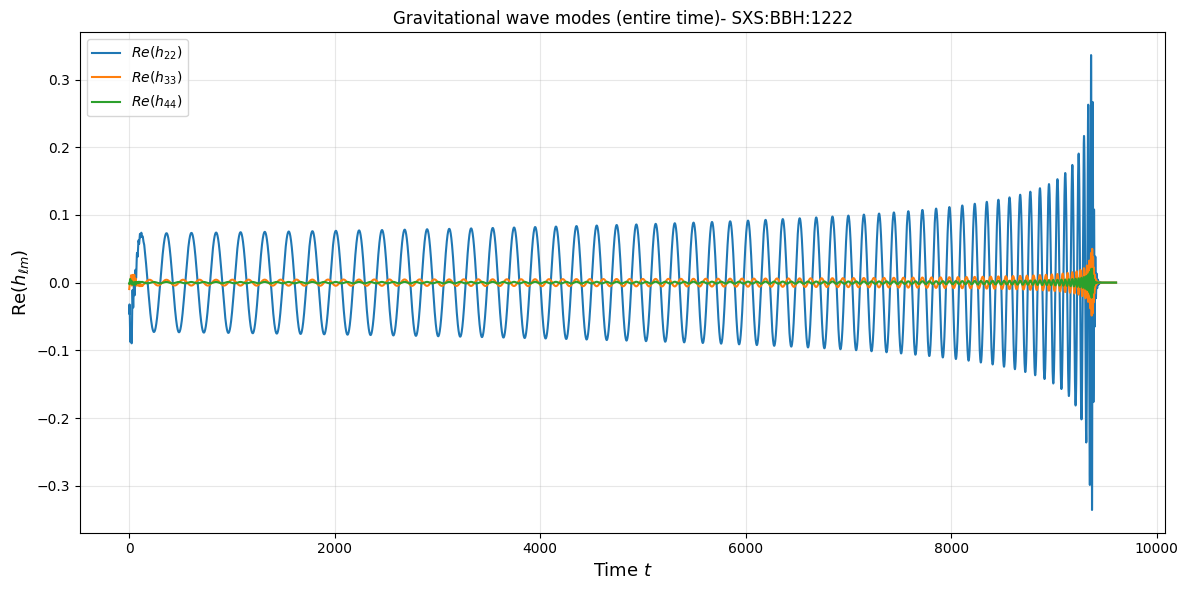

In [42]:

plt.figure(figsize=(12,6))

for l, m in modes:   #Implementing a "for-cycle" to plot the three modes

    plt.plot(
        t,
        h_real[(l,m)],
        label=fr'$Re(h_{{{l}{m}}})$'
    )

plt.xlabel(r'Time $t$', fontsize=13)
plt.ylabel(r'Re$(h_{\ell m})$', fontsize=13)

plt.title(f'Gravitational wave modes (entire time)- {sxs_id}')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Zooming into the early evolution $t<500$

In [43]:
early = t < 500

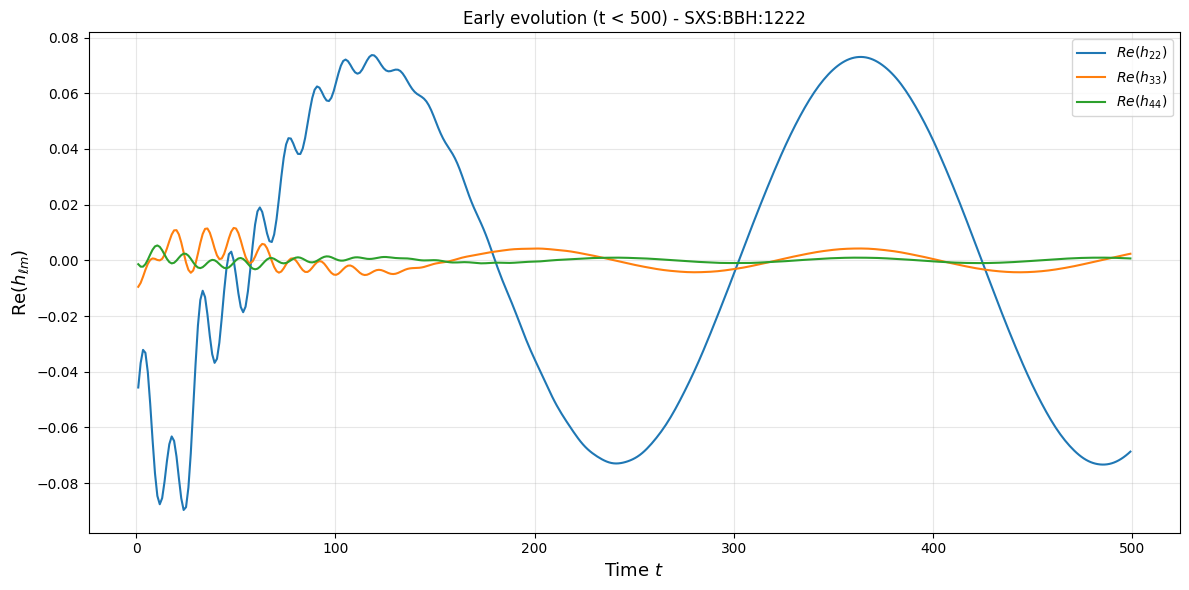

In [44]:
plt.figure(figsize=(12,6))

for l, m in modes:

    plt.plot(
        t[early],
        h_real[(l,m)][early],
        label=fr'$Re(h_{{{l}{m}}})$'
    )

plt.xlabel(r'Time $t$', fontsize=13)
plt.ylabel(r'Re$(h_{\ell m})$', fontsize=13)

plt.title(f'Early evolution (t < 500) - {sxs_id}')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

 Plot for the time-interval around merger and ringdown

First we found the amplitude of the dominant mode $(2,2)$

The $(2,2)$ mode is generally the dominant contribution to the gravitational-wave signal emitted by a quasi-circular binary black hole system. Therefore, we use the peak of its amplitude as an operational definition of the merger time:

$$
t_{\mathrm{merger}}=\underset{t}{\operatorname{arg\,max}}\,|h_{22}(t)|.
$$

This provides a consistent reference to identify the merger and ringdown stages and to compare the temporal evolution of the higher-order modes, such as $(3,3)$ and $(4,4)$.

In [45]:
# Amplitude of the (2,2) mode - to identify the merger
#((2,2) is the dominant mode)

h22 = np.array(w[:, w.index(2,2)])

A22 = np.abs(h22)

# Find the time of maximum amplitude

i_peak = np.argmax(A22)

t_merger = t[i_peak]

print("Approximate merger time:", t_merger)

Approximate merger time: 9365.242262426043


In [46]:
# Select merger and ringdown interval

merger = (
    (t >= t_merger - 100) &
    (t <= t_merger + 100)
)

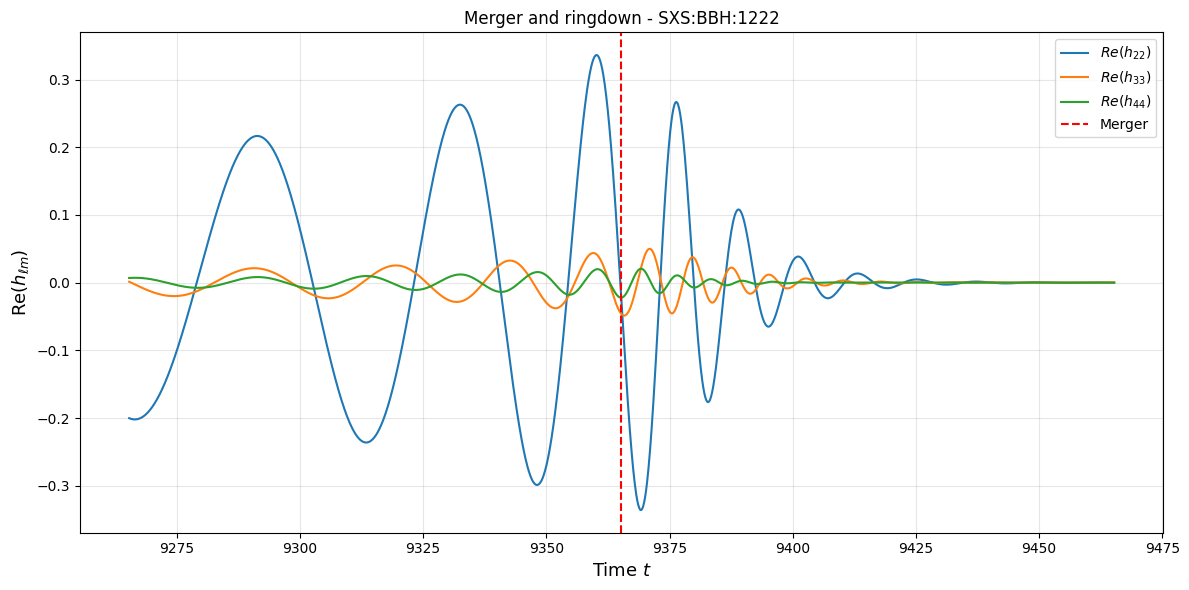

In [47]:
plt.figure(figsize=(12,6))

for l, m in modes:

    plt.plot(
        t[merger],
        h_real[(l,m)][merger],
        label=fr'$Re(h_{{{l}{m}}})$'
    )

plt.axvline(
    t_merger,
    color='red',
    linestyle='--',
    label='Merger'
)

plt.xlabel(r'Time $t$', fontsize=13)
plt.ylabel(r'Re$(h_{\ell m})$', fontsize=13)

plt.title(f'Merger and ringdown - {sxs_id}')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Section (b)
Maximum amplitudes of the gravitational-wave modes

For each of the six simulations, we calculate the maximum amplitude of the $(2,2)$, $(3,3)$, and $(4,4)$ modes.

The amplitude of each complex mode is defined as

$$
A_{\ell m}(t)=|h_{\ell m}(t)|.
$$

We then obtain its maximum over the entire waveform:

$$
\boxed{
A_{\max}^{\ell m}=\max_t |h_{\ell m}(t)|
}
$$

This gives three real numbers for each simulation, corresponding to the maximum amplitudes of the three selected modes.

We first investigate how these maximum amplitudes depend on the mass ratio $q$, and then compare the relative importance of the higher-order modes with respect to the dominant $(2,2)$ mode.

Furthermore, we plot $max$ $A^{l,m}$ vs $mass-ratio q$ for your simulations.

In [48]:
# Building a dictionary to collect the data

# Store maximum amplitudes dictionary

Amax = {
    (2,2): [],
    (3,3): [],
    (4,4): []
}

mass_ratios = []

# Extracting data from simulations

for sxs_id in IDs:

    # Retrieve metadata
    sim = catalog[sxs_id]

    q = sim['reference_mass_ratio']

    mass_ratios.append(q)

    # Retrieve waveform
    w = wf[sxs_id].h

    # Calculate maximum amplitude of each mode

    for l, m in modes:

        h_lm = np.array(w[:, w.index(l,m)])

        A_lm = np.abs(h_lm)

        Amax[(l,m)].append(np.max(A_lm))


In [49]:
for i, sxs_id in enumerate(IDs):
   # We use enumerate to iterate through a list while simultaneously
   #obtaining the index and the element.

    print(f"\nSimulation: {sxs_id}")
    print(f"Mass ratio q = {mass_ratios[i]}")

    for l, m in modes:

        print(f"Amax({l},{m}) = {Amax[(l,m)][i]}")


Simulation: SXS:BBH:1143
Mass ratio q = 1.250042584344006
Amax(2,2) = 0.38787348456178516
Amax(3,3) = 0.01929986593686477
Amax(4,4) = 0.021397377624834693

Simulation: SXS:BBH:1222
Mass ratio q = 1.9997081848720624
Amax(2,2) = 0.34424769121211124
Amax(3,3) = 0.05025342202608345
Amax(4,4) = 0.022219556800963113

Simulation: SXS:BBH:1178
Mass ratio q = 2.9999720509624472
Amax(2,2) = 0.2853186061234158
Amax(3,3) = 0.06092699046219981
Amax(4,4) = 0.022750181885887608

Simulation: SXS:BBH:1220
Mass ratio q = 4.000913819230769
Amax(2,2) = 0.24030215645485342
Amax(3,3) = 0.060459838666008986
Amax(4,4) = 0.023209596591154444

Simulation: SXS:BBH:0192
Mass ratio q = 6.579712082644992
Amax(2,2) = 0.1688537158799245
Amax(3,3) = 0.0506111078663392
Amax(4,4) = 0.020881008388944022

Simulation: SXS:BBH:1108
Mass ratio q = 9.199933130774635
Amax(2,2) = 0.12895978003466474
Amax(3,3) = 0.04174255059415765
Amax(4,4) = 0.018017286365809775


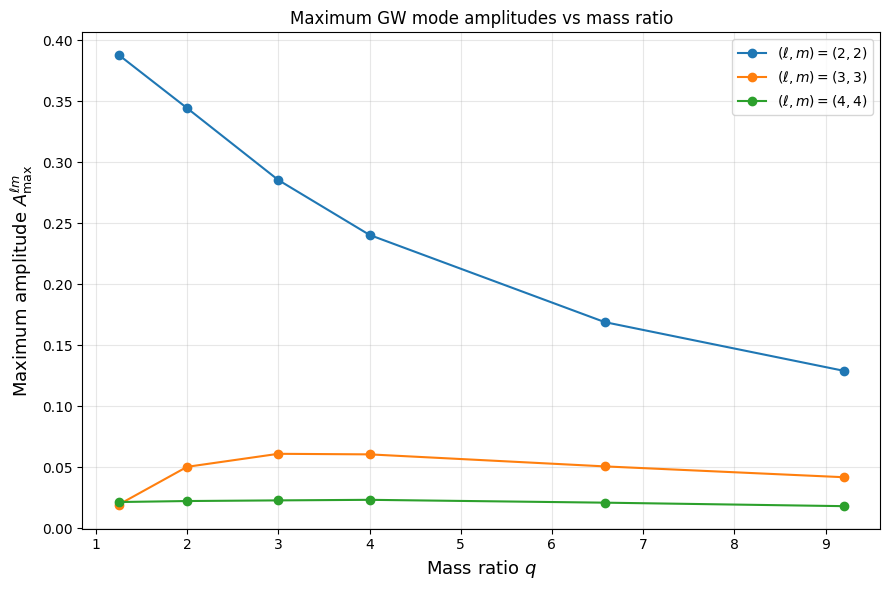

In [50]:
plt.figure(figsize=(9,6))

for l, m in modes:

    plt.plot(
        mass_ratios,
        Amax[(l,m)],
        'o-',
        label=fr'$(\ell,m)=({l},{m})$'
    )

plt.xlabel(r'Mass ratio $q$', fontsize=13)
plt.ylabel(r'Maximum amplitude $A_{\mathrm{max}}^{\ell m}$', fontsize=13)

plt.title('Maximum GW mode amplitudes vs mass ratio')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Relative importance of higher-order modes

In the previous analysis, we computed the maximum amplitudes of the gravitational-wave modes $(2,2)$, $(3,3)$, and $(4,4)$ for all six simulations.

Although the $(2,2)$ mode is dominant in all cases, comparing the absolute maximum amplitudes alone does not fully describe how the relative contribution of the higher-order modes changes with the mass ratio $(q)$.

In particular, the higher-order modes become more important relative to the dominant $(2,2)$ mode as the mass ratio increases.

To investigate this behavior, we define the following amplitude ratios:
$$
R_{33} =
\frac{A_{\max}^{3,3}}{A_{\max}^{2,2}},
\qquad
R_{44} =
\frac{A_{\max}^{4,4}}{A_{\max}^{2,2}}.
$$

These dimensionless quantities measure the maximum amplitude of each higher-order mode relative to that of the dominant mode.

By normalizing the amplitudes with respect to $(A_{\max}^{2,2})$, we can compare the relative strength of the higher-order modes independently of the overall amplitude scale of each simulation.

Therefore, plotting $(R_{33})$ and $(R_{44})$ as functions of the mass ratio $(q)$ allows us to investigate whether the relative contribution of higher-order modes increases as the mass asymmetry of the binary system becomes larger.

This provides a complementary characterization of the multipolar structure of the gravitational-wave emission.

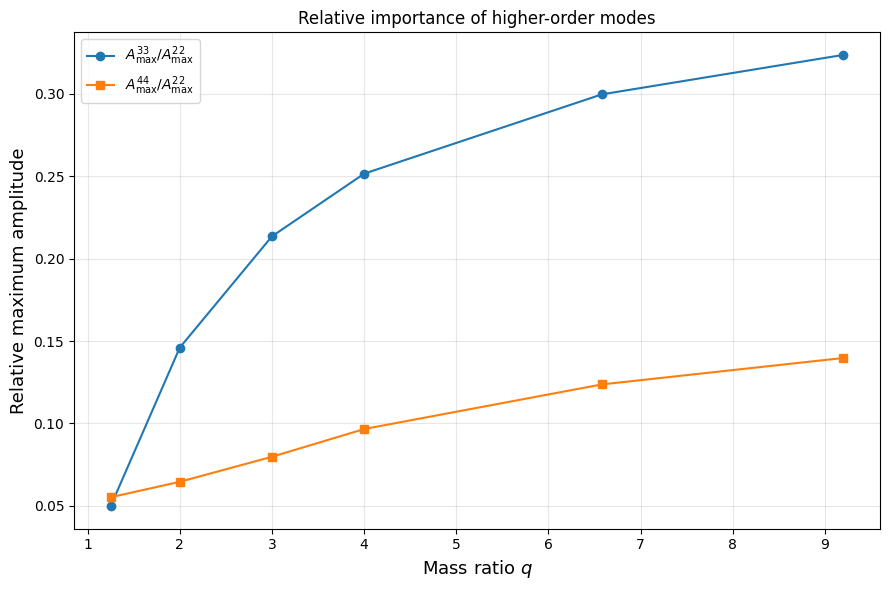

In [51]:

# Relative importance of higher-order modes


# Relative amplitudes
R33 = np.array(Amax[(3,3)]) / np.array(Amax[(2,2)])

R44 = np.array(Amax[(4,4)]) / np.array(Amax[(2,2)])

# Plot
plt.figure(figsize=(9,6))

plt.plot(
    mass_ratios,
    R33,
    'o-',
    label=r'$A_{\max}^{33}/A_{\max}^{22}$'
)

plt.plot(
    mass_ratios,
    R44,
    's-',
    label=r'$A_{\max}^{44}/A_{\max}^{22}$'
)

plt.xlabel(r'Mass ratio $q$', fontsize=13)

plt.ylabel('Relative maximum amplitude', fontsize=13)

plt.title('Relative importance of higher-order modes')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Explanation:
The relative amplitude ratios exhibit an increasing trend with the mass ratio $(q)$ for both higher-order modes.

For the (3,3) mode, the ratio $(R_{33})$ increases significantly, from approximately (0.05) to (0.32). This indicates that the maximum amplitude of this mode becomes increasingly important relative to the dominant $(2,2)$ mode.

Similarly, the $(4,4)$ mode exhibits an increase in its relative amplitude, with $(R_{44})$ growing from approximately $(0.055)$ to $(0.14)$. However, this increase is more moderate than that observed for the $(3,3)$ mode.

## Section (c)
Relation between amplitude $max$ $A^{22}$ and mass ratio $ν$

In [52]:

# Symmetric mass ratio:  nu

q = np.array(mass_ratios)

nu = q / (1 + q)**2

for i in range(len(q)):
    print(f"q = {q[i]:.3f}, nu = {nu[i]:.4f}")

q = 1.250, nu = 0.2469
q = 2.000, nu = 0.2222
q = 3.000, nu = 0.1875
q = 4.001, nu = 0.1600
q = 6.580, nu = 0.1145
q = 9.200, nu = 0.0884


### Proportionality between the maximum $(2,2)$ mode amplitude and the symmetric mass ratio

To investigate the dependence of the maximum $(2,2)$ mode amplitude on the symmetric mass ratio, we perform a linear fit of the form

$$
A_{\max}^{22}=C\nu,
\qquad
\nu=\frac{q}{(1+q)^2}.
$$

The proportionality coefficient $C $ is obtained by minimizing the sum of squared residuals,

$$
S(C)=\sum_i\left(A_{\max,i}^{22}-C\nu_i\right)^2.
$$

Setting \(dS/dC=0\) gives

$$
C=\frac{\sum_i\nu_i A_{\max,i}^{22}}
{\sum_i\nu_i^2}.
$$

For our six simulations, the fit yields $A_{\max}^{22}\approx 1.536\,\nu$

The numerical results therefore show an approximately proportional dependence of the maximum $(2,2)$ mode amplitude on the symmetric mass ratio.

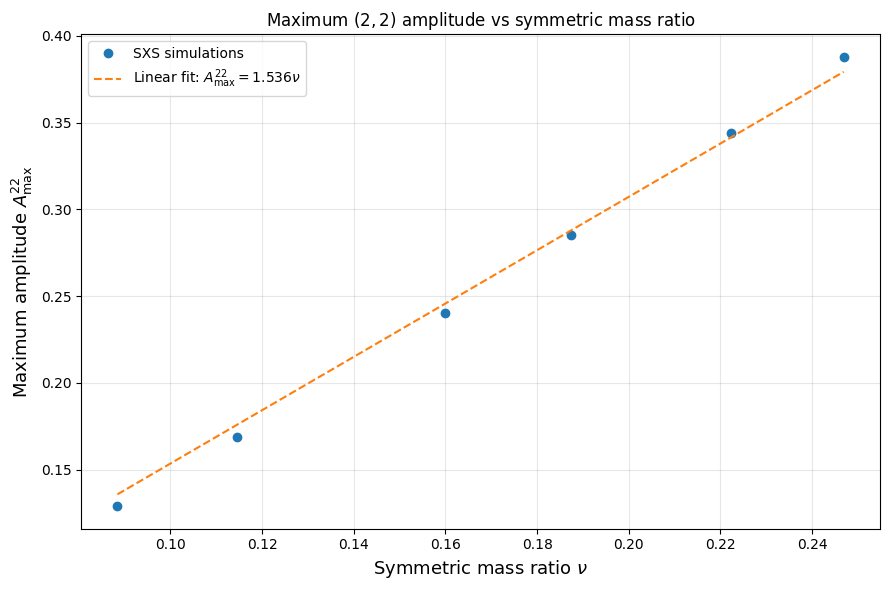

Proportionality coefficient C = 1.535922867387971
Proportionality coefficient C = 1.535922867387971
R-squared = 0.995672331917517


In [53]:
# Maximum (2,2) amplitude vs symmetric mass ratio

A22_max = np.array(Amax[(2,2)])

# Sort data by symmetric mass ratio
idx = np.argsort(nu)

nu_sorted = nu[idx]
A22_sorted = A22_max[idx]


# Linear proportional fit: A22_max = C * nu
# least-squares fit of the form:
C = np.sum(nu_sorted * A22_sorted) / np.sum(nu_sorted**2)

A22_fit = C * nu_sorted

# Plot
plt.figure(figsize=(9,6))

plt.plot(
    nu_sorted,
    A22_sorted,
    'o',
    label=r'SXS simulations'
)

plt.plot(
    nu_sorted,
    A22_fit,
    '--',
    label=fr'Linear fit: $A_{{\max}}^{{22}}={C:.3f}\nu$'
)

plt.xlabel(r'Symmetric mass ratio $\nu$', fontsize=13)
plt.ylabel(r'Maximum amplitude $A_{\max}^{22}$', fontsize=13)

plt.title(r'Maximum $(2,2)$ amplitude vs symmetric mass ratio')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("Proportionality coefficient C =", C)

# Goodness of fit

SS_res = np.sum((A22_sorted - A22_fit)**2)
SS_tot = np.sum((A22_sorted - np.mean(A22_sorted))**2)

R2 = 1 - SS_res / SS_tot

print("Proportionality coefficient C =", C)
print("R-squared =", R2)

### Explanation: Maximum $(2,2)$ amplitude vs. symmetric mass ratio

We investigate the dependence of the maximum amplitude of the dominant $(2,2$) mode on the symmetric mass ratio $\nu=\frac{q}{(1+q)^2}$

The numerical results show an approximately linear relationship:


$$\boxed{A_{\max}^{2,2}\approx 1.536\,\nu}$$

Therefore, the maximum amplitude decreases as the mass ratio \(q\) increases, consistently with the expected behavior described in the exercise.

# Problem 3: Black Hole Kicks

The binaries we are interested in are non-spinning and have a z → −z symmetry. This implies that
GW emission above and below the equatorial plane is equal so that the z-component of the kick will
vanish, and that we only need to compute the linear momentum emission tangential to the orbital
plane.


To utilize GW modes $h^{l,m}$, we use the GW-linear momentum flux expressed in terms of the $h^{l,m}(t)$ modes and the Newman-Penrose scalar $Ψ_{4}$.

The linear momentum flux (main formula) carried by gravitational waves in the orbital plane is given by:

$$
\boxed{
\frac{dP_+}{dt}
=
\frac{dP_x}{dt}
+i\frac{dP_y}{dt}
=
\frac{1}{8\pi}
\sum_{\ell,m}
\dot h_{\ell m}
\left[
a_{\ell m}\dot h^*_{\ell,m+1}
+b_{\ell,-m}\dot h^*_{\ell-1,m+1}
-b_{\ell+1,m+1}\dot h^*_{\ell+1,m+1}
\right]
}
\tag{2}
$$

where $\dot h_{\ell m}$ denotes the first time derivative of the gravitational-wave mode $h_{\ell m}$, and the asterisk denotes complex conjugation.
The coefficients $a_{\ell m}$ and $b_{\ell m}$ are defined in Ruiz et al.



### Section (a)

For one simulation, plot as a function of time $h^{2,2}$ and $\dot{h}^{2,2}$ on the same plot.  

In [54]:
# Extracting time-derivatives h'^{l,m} with sxs through wdot=w.h.dot


# Select one simulation (Option 2)

sxs_id = IDs[2]

# Retrieve simulation object
w = wf[sxs_id]

# Extract waveform and its time derivative

h = w.h
hdot = h.dot

# Time array
t = np.array(h.t)


# Extract (2,2) mode

h22 = np.array(h[:, h.index(2,2)])

hdot22 = np.array(
    hdot[:, hdot.index(2,2)]
)

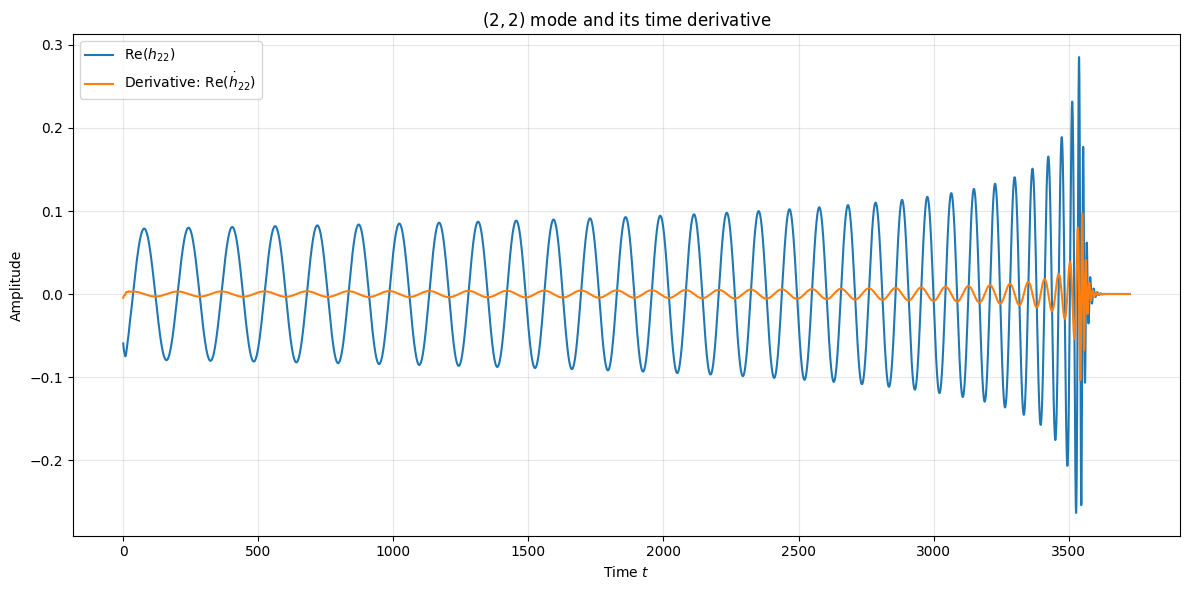

In [55]:
## Plotting

plt.figure(figsize=(12,6))

plt.plot(
    t,
    np.real(h22),
    label=r'Re$(h_{22})$'
)

plt.plot(
    t,
    np.real(hdot22),
    label=r'Derivative: Re$(\dot{h}_{22})$'
)

plt.xlabel(r'Time $t$')
plt.ylabel('Amplitude')

plt.title(r'$(2,2)$ mode and its time derivative')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Explanation of the plot above
The derivative (orange curve) exhibits the expected behavior, following the oscillations of the original waveform and becoming more pronounced near merger.

### Section (b)
Implement Eq. (2) as a python function that computes the GW linear momentum flux dP+/dt as a time-series, given a waveform object.

The coefficients $a_{\ell,m}$ and $b_{\ell,m}$ given by Ruiz et al. are defined as:



$$
\boxed{
a_{\ell,m} =
\frac{\sqrt{(\ell-m)(\ell+m+1)}}
{\ell(\ell+1)}
}
$$

and

$$
\boxed{
b_{\ell,m} =
\frac{1}{2\ell}
\sqrt{
\frac{
(\ell-2)(\ell+2)(\ell+m)(\ell+m-1)
}{
(2\ell-1)(2\ell+1)
}
}
}
$$

These coefficients determine the coupling between different gravitational-wave modes in the linear momentum flux.

In [56]:
# Construction of the coefficients a and b


def a_coeff(l, m):

    # Check valid indices
    # For GWs in General relativity: l>=2 and |m|<= l
    if l < 2 or abs(m) > l or abs(m+1) > l:
        return 0.0

    return np.sqrt((l-m)*(l+m+1)) / (l*(l+1))


def b_coeff(l, m):

    # Check valid indices
    if l < 2 or abs(m) > l:
        return 0.0

    return (1/(2*l)) * np.sqrt(
        ((l-2)*(l+2)*(l+m)*(l+m-1)) /
        ((2*l-1)*(2*l+1))
    )


# Test coupling coefficients

print("a(2,1) =", a_coeff(2,1))
print("a(2,2) =", a_coeff(2,2))

print("b(3,1) =", b_coeff(3,1))
print("b(2,1) =", b_coeff(2,1))

a(2,1) = 0.3333333333333333
a(2,2) = 0.0
b(3,1) = 0.21821789023599236
b(2,1) = 0.0


### Implementing a function of the linear momentum flux
This function will recieve hdot and return the complex flow - following the equation (2).

In [57]:
# Linear momentum flux function

def momentum_flux(hdot):

    # Available multipolar modes

    modes = set(map(tuple, hdot.LM))
    lmax = min(8, max(l for l, m in modes))

    # Complex time series: Initializing the flow
    # We use a complex type due to dP contains
    # a real part and a complex part
    #given by idP_y/dt

    dPplus_dt = np.zeros(len(hdot.t), dtype=complex)

    # Retrieve a mode, or zero if unavailable

    def get_mode(l, m):

      #conditions to avoid unavailable modes

        if l < 2 or l > lmax or abs(m) > l:
            return 0.0
        if (l, m) not in modes:
            return 0.0
        return np.asarray(hdot[:, hdot.index(l, m)])

    # Sum over all available modes

    for l, m in sorted(modes):

        if l < 2 or l > lmax:
            continue

        hlm = get_mode(l, m)

        # First coupling in eq (2)
        term1 = (
            a_coeff(l, m)
            * np.conj(get_mode(l, m+1))
        )

        # Second coupling in eq (2)
        term2 = (
            b_coeff(l, -m)
            * np.conj(get_mode(l-1, m+1))
        )

        # Third coupling in eq (2)
        term3 = (
            b_coeff(l+1, m+1)
            * np.conj(get_mode(l+1, m+1))
        )

 #Full main function:

        dPplus_dt += hlm * (term1 + term2 - term3)

    return dPplus_dt / (8*np.pi)

In [58]:
dPplus_dt = momentum_flux(hdot)

print("Shape:", dPplus_dt.shape)
print("Data type:", dPplus_dt.dtype)
print("First values:", dPplus_dt[:5])

Shape: (14036,)
Data type: complex128
First values: [1.48327290e-06-1.32280732e-06j 1.52932604e-06-1.60606437e-06j
 1.34212159e-06-1.27303181e-06j 9.73435600e-07-6.82244706e-07j
 6.13273833e-07-4.27699776e-07j]


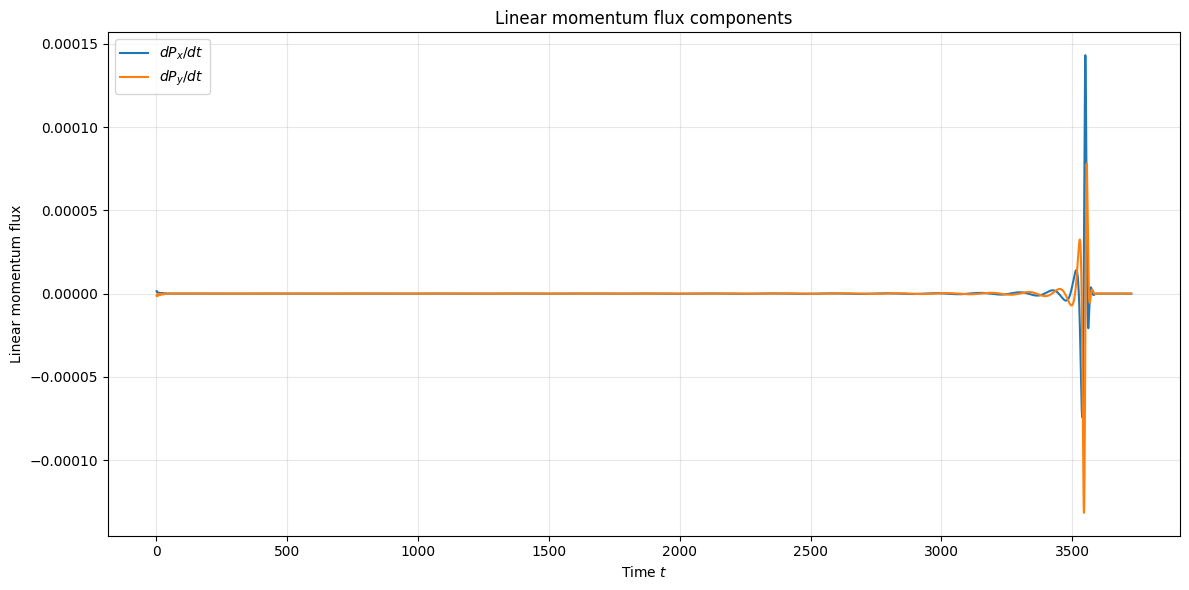

In [59]:
# Linear momentum flux components

plt.figure(figsize=(12,6))

plt.plot(t, np.real(dPplus_dt), label=r'$dP_x/dt$')
plt.plot(t, np.imag(dPplus_dt), label=r'$dP_y/dt$')

plt.xlabel(r'Time $t$')
plt.ylabel('Linear momentum flux')

plt.title('Linear momentum flux components')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#Section (c)
Evaluate $dP_{+}/dt$ and compute a cumulative integral of the emitted linear momentum up to time t, as a funcion of time:

$$
P_{+}(t)=\int_{t_{start}}^{t}\frac{dP_{+}(t')}{dt'}dt',
$$

where $t_{start}=t[0]$.

In [60]:

# Cumulative linear momentum from the beginning of the dataset

# Time array associated with the waveform
t = np.asarray(hdot.t)

dt = np.diff(t)

dP_intervals = 0.5 * (
    dPplus_dt[1:] + dPplus_dt[:-1]
) * dt

Pplus = np.concatenate((
    np.array([0j]),
    np.cumsum(dP_intervals)
))

# Extract Cartesian components
Px = np.real(Pplus)
Py = np.imag(Pplus)


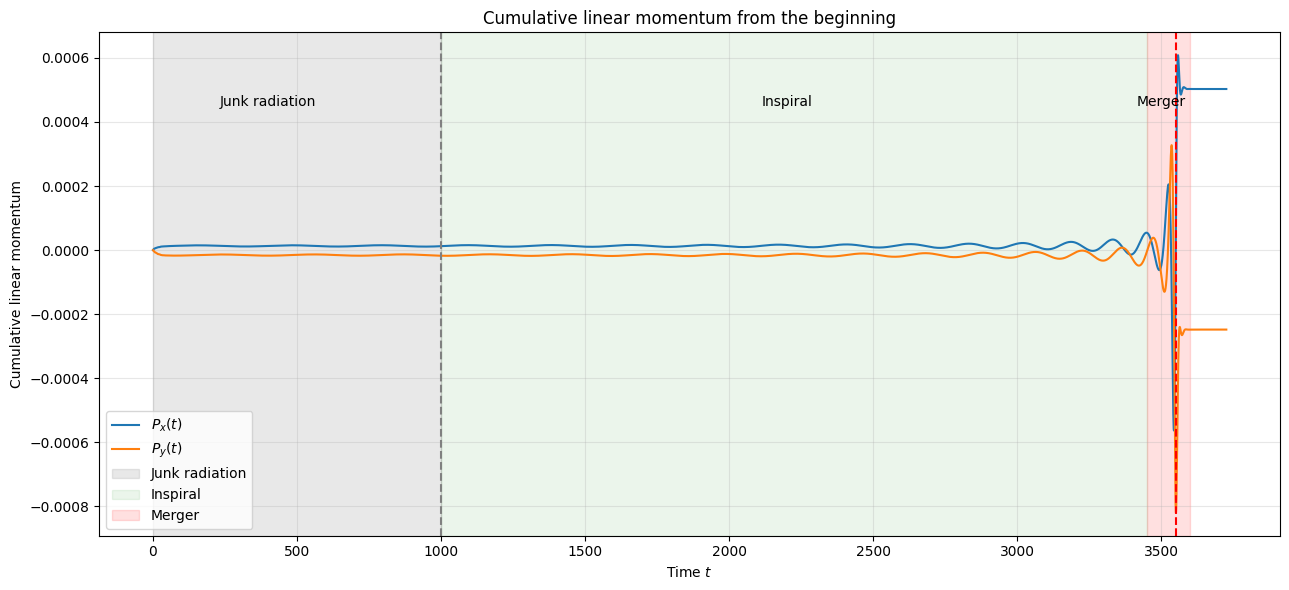

In [61]:
plt.figure(figsize=(13,6))

plt.plot(t, Px, label=r'$P_x(t)$')
plt.plot(t, Py, label=r'$P_y(t)$')


# 1. Junk radiation
plt.axvspan(0, 1000, color='gray', alpha=0.18,
            label='Junk radiation')

# 2. Inspiral
plt.axvspan(1000, 3450, color='green', alpha=0.08,
            label='Inspiral')

# 3. Merger
plt.axvspan(3450, 3600, color='red', alpha=0.12,
            label='Merger')

# Mark t = 1000
plt.axvline(1000, color='gray', linestyle='--', linewidth=1.5)

# Mark approximate merger time
plt.axvline(3550, color='red', linestyle='--', linewidth=1.5)

# Annotations
plt.text(400, 0.00045, 'Junk radiation',
         ha='center', fontsize=10)

plt.text(2200, 0.00045, 'Inspiral',
         ha='center', fontsize=10)

plt.text(3500, 0.00045, 'Merger',
         ha='center', fontsize=10)

plt.xlabel(r'Time $t$')
plt.ylabel('Cumulative linear momentum')
plt.title('Cumulative linear momentum from the beginning')

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of the cumulative linear momentum - including the junk radiation

The plot shows the time evolution of the cumulative linear momentum, obtained by integrating the momentum flux from the beginning of the simulation, $t_{\mathrm{start}}=t[0]$.

Three different stages can be identified:

- **Junk radiation $(t<1000)$:** Small initial variations in the accumulated momentum are associated with the spurious radiation present at the beginning of the numerical simulation.
- **Inspiral $(1000 \lesssim t<3450)$:** The momentum components $(P_x(t))$ and $(P_y(t))$ exhibit small oscillations, indicating a gradual accumulation of linear momentum during the inspiral.
- **Merger $(t\approx3550)$:** Both components undergo a sharp variation, corresponding to the dominant contribution to the radiated linear momentum during the merger and ringdown.



### Section (d):
For all the simulation, compute the cumulative linear momentum emitted from $t=1000$ to the end of the waveform:

$$
P_{x}+iP_{y}=\int_{1000}^{t_{end}} \frac{dP _{+}(t')}{dt'}dt'.
$$

The emitted linear momentum must be equal to linear momentum $v_{kick}m_{f}$ of the remnant black hole which has mass $m_{f}$.

Therefore, the remnant kick velocity is given by:

$$
v_{kick}=\frac{\sqrt{P_{x}^{2}+P_{y}^{2}}}{m_{f}}
$$

In [62]:
#main function
def compute_kick(w, mf, t_cut=1000):

    # 1. Extract waveform and its time derivative
    hdot = w.h.dot

    # 2. Compute linear momentum flux
    dPplus_dt = momentum_flux(hdot)

    # 3. Extract time array
    t = np.asarray(hdot.t)

    # 4. Exclude junk radiation
    mask = t >= t_cut

    t_phys = t[mask]
    dP_phys = dPplus_dt[mask]

    # 5. Compute time intervals
    dt = np.diff(t_phys)

    # 6. Trapezoidal integration using numpy.cumsum
    dP_intervals = 0.5 * (
        dP_phys[1:] + dP_phys[:-1]
    ) * dt

    Pplus = np.concatenate((
        np.array([0j]),
        np.cumsum(dP_intervals)
    ))

    # 7. Final Cartesian momentum components
    Px = np.real(Pplus[-1])
    Py = np.imag(Pplus[-1])

    # 8. Compute recoil velocity
    P_rad = np.sqrt(Px**2 + Py**2)

    v_kick = P_rad / mf

    return Px, Py, v_kick

In [63]:
# Compute the kick velocity for all simulations

q_values = []
kick_values = []

for sxs_id in IDs:

    # Retrieve simulation data
    w = wf[sxs_id]
    sim = catalog[sxs_id]

    # Mass ratio and remnant mass
    q = sim['reference_mass_ratio']
    mf = sim['remnant_mass']

    # Compute kick
    Px, Py, v_kick = compute_kick(w, mf)

    # Store results
    q_values.append(q)
    kick_values.append(v_kick)

    print(f"Simulation: {sxs_id}")
    print(f"Mass ratio: {q:.4f}")
    print(f"Kick velocity: {v_kick:.6e} c")
    print(f"Kick velocity: {v_kick*299792.458:.4f} km/s")
    print("----------------------------------")

Simulation: SXS:BBH:1143
Mass ratio: 1.2500
Kick velocity: 1.910292e-04 c
Kick velocity: 57.2691 km/s
----------------------------------
Simulation: SXS:BBH:1222
Mass ratio: 1.9997
Kick velocity: 4.668792e-04 c
Kick velocity: 139.9669 km/s
----------------------------------
Simulation: SXS:BBH:1178
Mass ratio: 3.0000
Kick velocity: 5.581787e-04 c
Kick velocity: 167.3378 km/s
----------------------------------
Simulation: SXS:BBH:1220
Mass ratio: 4.0009
Kick velocity: 5.063679e-04 c
Kick velocity: 151.8053 km/s
----------------------------------
Simulation: SXS:BBH:0192
Mass ratio: 6.5797
Kick velocity: 3.467004e-04 c
Kick velocity: 103.9382 km/s
----------------------------------
Simulation: SXS:BBH:1108
Mass ratio: 9.1999
Kick velocity: 2.338365e-04 c
Kick velocity: 70.1024 km/s
----------------------------------


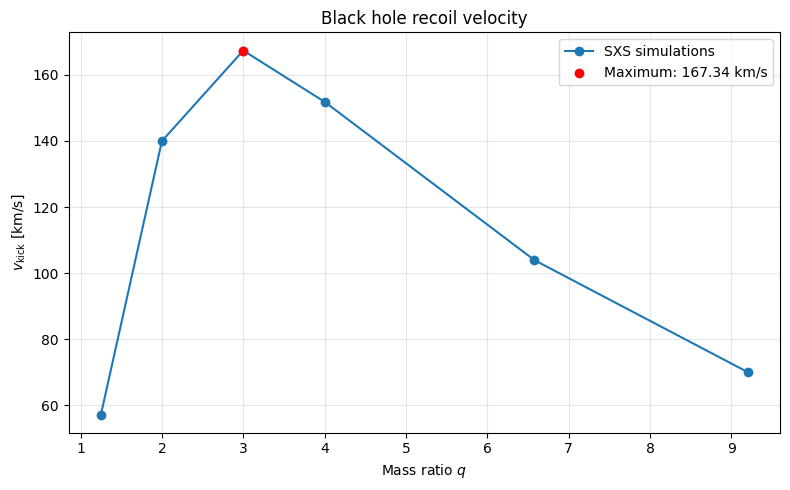

In [64]:
#Plot

# Convert kick velocities from units of c to km/s
kick_kms = np.array(kick_values) * 299792.458
q_values = np.array(q_values)

# Find maximum kick
imax = np.argmax(kick_kms)

plt.figure(figsize=(8,5))

plt.plot(q_values, kick_kms, 'o-', label='SXS simulations')

plt.scatter(q_values[imax], kick_kms[imax],
            color='red', zorder=3,
            label=f'Maximum: {kick_kms[imax]:.2f} km/s')

plt.xlabel(r'Mass ratio $q$')
plt.ylabel(r'$v_{\mathrm{kick}}$ [km/s]')
plt.title('Black hole recoil velocity')
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Recoil velocity as a function of the mass ratio

The recoil velocity was computed for the six SXS simulations by integrating the gravitational-wave linear momentum flux from $(t=1000)$ to the end of each waveform, thereby excluding the initial contribution from junk radiation.

The resulting kick velocities increase with the mass ratio up to approximately $(q=3)$, where the maximum value is obtained:

$$
v_{\mathrm{kick}}^{\max}\approx167.34\ \mathrm{km/s}.
$$

For larger mass ratios, the recoil velocity decreases. Thus, the results exhibit a non-monotonic dependence on the mass ratio, with a maximum around $(q=3)$.

### Binary black hole coalescence: waveform and cumulative momentum (didactic)

The following code illustrates the different stages of a binary black hole coalescence by displaying the gravitational-wave amplitude and the cumulative linear momentum in a single figure.

In [65]:
# Select simulation
sxs_id = IDs[2]
w = wf[sxs_id]

# Extract waveform
h = w.h
t_h = np.asarray(h.t)

# Extract (2,2) mode
h22 = np.asarray(h[:, h.index(2,2)])

# Find merger time
i_merger = np.argmax(np.abs(h22))
t_merger = t_h[i_merger]

print("Merger time:", t_merger)

Merger time: 3538.3770122858036


In [66]:
# Recover cumulative momentum components
Px_cum = np.real(Pplus)
Py_cum = np.imag(Pplus)

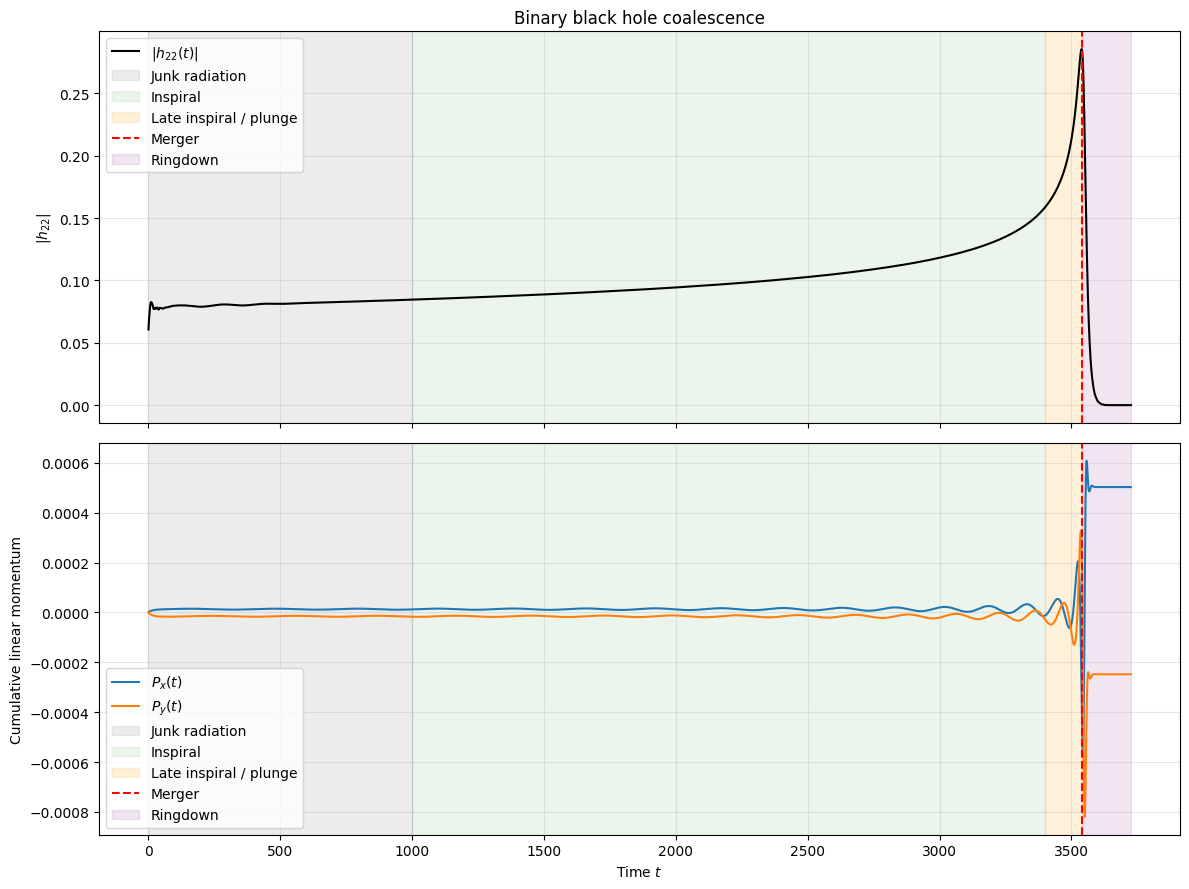

In [67]:
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12,9), sharex=True
)


# Top panel: waveform amplitude


ax1.plot(t_h, np.abs(h22), color='black',
         label=r'$|h_{22}(t)|$')


# Bottom panel: cumulative momentum

ax2.plot(t, Px_cum, label=r'$P_x(t)$')
ax2.plot(t, Py_cum, label=r'$P_y(t)$')




# Coalescence stages (both panels)


for ax in (ax1, ax2):

    # Junk radiation
    ax.axvspan(0, 1000, color='gray',
               alpha=0.15, label='Junk radiation')

    # Inspiral
    ax.axvspan(1000, 3400, color='green',
               alpha=0.08, label='Inspiral')

    # Late inspiral / plunge
    ax.axvspan(3400, t_merger, color='orange',
               alpha=0.15, label='Late inspiral / plunge')

    # Merger time
    ax.axvline(t_merger, color='red',
               linestyle='--', label='Merger')

    # Ringdown
    ax.axvspan(t_merger, t_h[-1], color='purple',
               alpha=0.10, label='Ringdown')


# Labels


ax1.set_ylabel(r'$|h_{22}|$')
ax1.set_title('Binary black hole coalescence')

ax2.set_xlabel(r'Time $t$')
ax2.set_ylabel('Cumulative linear momentum')

ax1.legend()
ax2.legend()

ax1.grid(alpha=0.3)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Explanation:
The upper panel shows the amplitude of the dominant gravitational-wave mode, $|h_{22}(t)|$, while the lower panel displays the cumulative linear momentum radiated in the $(x)$ and $(y)$ directions.

The shaded regions distinguish the initial junk radiation, inspiral, late inspiral/plunge, merger, and ringdown stages. The merger time is identified by the maximum of the $(2,2)$ mode amplitude.

This visualization helps illustrate how the emission of linear momentum becomes particularly significant near merger, while the cumulative momentum approaches approximately constant values during ringdown.

### Section (e)

Comparing with symmetric mass. Use Gonzalez

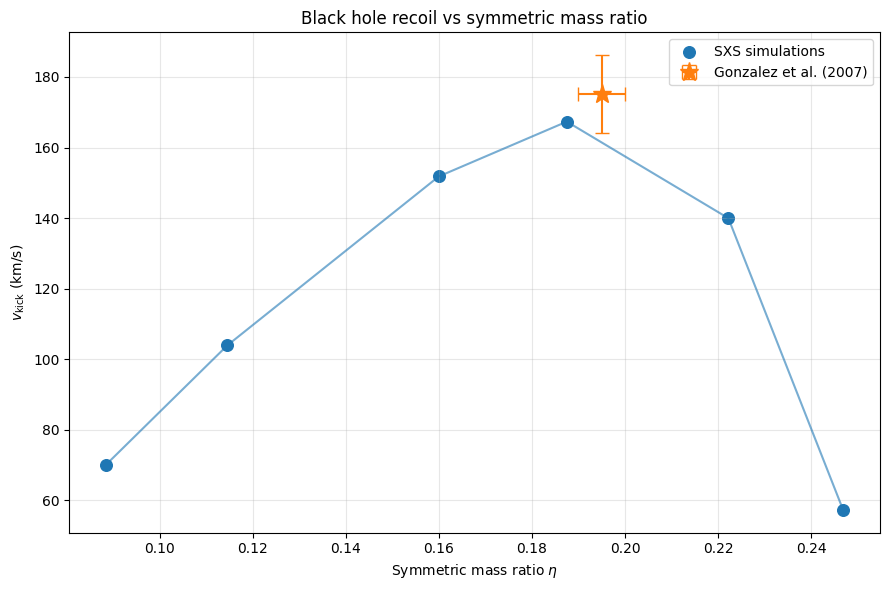

In [68]:

# Symmetric mass ratio
eta_values = q_values / (1 + q_values)**2

# Sort results by symmetric mass ratio
order = np.argsort(eta_values)

eta_sorted = eta_values[order]
kick_sorted = kick_kms[order]

plt.figure(figsize=(9,6))

plt.scatter(
    eta_sorted,
    kick_sorted,
    s=70,
    label='SXS simulations'
)

plt.plot(
    eta_sorted,
    kick_sorted,
    alpha=0.6
)

# Gonzalez et al. (2007)
plt.errorbar(
    0.195, 175.2,
    xerr=0.005,
    yerr=11,
    fmt='*',
    markersize=14,
    capsize=5,
    label='Gonzalez et al. (2007)'
)

plt.xlabel(r'Symmetric mass ratio $\eta$')
plt.ylabel(r'$v_{\mathrm{kick}}$ (km/s)')
plt.title('Black hole recoil vs symmetric mass ratio')

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Comparison with González et al. (2007)

To compare our results with González et al. (2007), we express the recoil velocity as a function of the symmetric mass ratio,

$$
\eta=\frac{q}{(1+q)^2}.
$$

Our simulations yield a maximum recoil velocity of approximately

$$
v_{\mathrm{kick}}^{\max}\approx167.34\ \mathrm{km/s},
$$

obtained at $q\approx3$, corresponding to $\eta=0.1875$.

González et al. (2007) reported a maximum kick velocity of $175.2\pm11\ \mathrm{km/s}$ at a symmetric mass ratio of $\eta=0.195\pm0.005$.

Our maximum recoil velocity is close to the value reported by González et al. (2007). The corresponding symmetric mass ratio is also close to their reported value, although our discrete set of simulations does not sample the location of the maximum exactly. The results also reproduce the non-monotonic dependence of the recoil velocity on the mass ratio.